
# ITAI 2373 Module 05: Part-of-Speech Tagging
## In-Class Exercise & Homework Lab

Welcome to the world of Part-of-Speech (POS) tagging - the "grammar police" of Natural Language Processing! 🚔📝

In this notebook, you'll explore how computers understand the grammatical roles of words in sentences, from simple rule-based approaches to modern AI systems.

### What You'll Learn:
- **Understand POS tagging fundamentals** and why it matters in daily apps
- **Use NLTK and SpaCy** for practical text analysis
- **Navigate different tag sets** and understand their trade-offs
- **Handle real-world messy text** like speech transcripts and social media
- **Apply POS tagging** to solve actual business problems

### Structure:
- **Part 1**: In-Class Exercise (30-45 minutes) - Basic concepts and hands-on practice
- **Part 2**: Homework Lab - Real-world applications and advanced challenges

---

*💡 **Pro Tip**: POS tagging is everywhere! It helps search engines understand "Apple stock" vs "apple pie", helps Siri understand your commands, and powers autocorrect on your phone.*



## 🛠️ Setup and Installation

Let's get our tools ready! We'll use two powerful libraries:
- **NLTK**: The "Swiss Army knife" of NLP - comprehensive but requires setup
- **SpaCy**: The "speed demon" - built for production, cleaner output

Run the cells below to install and set up everything we need.


In [1]:

# Install required libraries (run this first!)
!pip install nltk spacy matplotlib seaborn pandas
!python -m spacy download en_core_web_sm

print("✅ Installation complete!")


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 73.6 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
✅ Installation complete!


In [2]:

# Import all the libraries we'll need
import nltk
import spacy
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import warnings
warnings.filterwarnings('ignore')

# Download NLTK data (this might take a moment)
nltk.download('punkt')
nltk.download('averaged_perceptron_tagger')
nltk.download('universal_tagset')

# Load SpaCy model
nlp = spacy.load('en_core_web_sm')

print("🎉 All libraries loaded successfully!")
print("📚 NLTK version:", nltk.__version__)
print("🚀 SpaCy version:", spacy.__version__)


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger.zip.
[nltk_data] Downloading package universal_tagset to /root/nltk_data...
[nltk_data]   Unzipping taggers/universal_tagset.zip.


🎉 All libraries loaded successfully!
📚 NLTK version: 3.9.1
🚀 SpaCy version: 3.8.16



---
# 🎯 PART 1: IN-CLASS EXERCISE (30-45 minutes)

Welcome to the hands-on portion! We'll start with the basics and build up your understanding step by step.

## Learning Goals for Part 1:
1. Understand what POS tagging does
2. Use NLTK and SpaCy for basic tagging
3. Interpret and compare different tag outputs
4. Explore word ambiguity with real examples
5. Compare different tagging approaches



## 🔍 Activity 1: Your First POS Tags (10 minutes)

Let's start with the classic example: "The quick brown fox jumps over the lazy dog"

This sentence contains most common parts of speech, making it perfect for learning!


In [8]:
sentence = "The quick brown fox jumps over the lazy dog"

import nltk
nltk.download('punkt')
nltk.download('averaged_perceptron_tagger')
nltk.download('universal_tagset')
nltk.download('punkt_tab')
nltk.download('averaged_perceptron_tagger_eng')
tokens = nltk.word_tokenize(sentence)
pos_tags = nltk.pos_tag(tokens)

print("Original sentence:", sentence)
print("\nTokens:", tokens)
print("\nPOS Tags:")
for word, tag in pos_tags:
    print(f"  {word:8} -> {tag}")

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package universal_tagset to /root/nltk_data...
[nltk_data]   Package universal_tagset is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger_eng.zip.


Original sentence: The quick brown fox jumps over the lazy dog

Tokens: ['The', 'quick', 'brown', 'fox', 'jumps', 'over', 'the', 'lazy', 'dog']

POS Tags:
  The      -> DT
  quick    -> JJ
  brown    -> NN
  fox      -> NN
  jumps    -> VBZ
  over     -> IN
  the      -> DT
  lazy     -> JJ
  dog      -> NN



### 🤔 Quick Questions:
1. What does 'DT' mean? What about 'JJ'?
I think DT means its something to put words in a group, as DT comes up for "the" or have same grammatical play. JJ I think the pronouns or way to categorized the words in the same group.
2. Why do you think 'brown' and 'lazy' have the same tag?
Brown and lazy having the same tag, I think it's something to put them in the same group by meaning.
3. Can you guess what 'VBZ' represents?
VBZ represents the grammaticial meaning of someone doing something as it pop up for jumps.
*Hint: Think about the grammatical role each word plays in the sentence!*



## 🚀 Activity 2: SpaCy vs NLTK Showdown (10 minutes)

Now let's see how SpaCy handles the same sentence. SpaCy uses cleaner, more intuitive tag names.


In [11]:
import spacy
nlp = spacy.load('en_core_web_sm')
# Hint: Use nlp(sentence) and access .text and .pos_ attributes
doc = nlp(sentence)

print("SpaCy POS Tags:")
for token in doc:
    print(f"  {token.text:8} -> {token.pos_:6} ({token.tag_})")

print("\n" + "="*50)
print("COMPARISON:")
print("="*50)

# Let's compare side by side
nltk_tags = nltk.pos_tag(nltk.word_tokenize(sentence))
spacy_doc = nlp(sentence)

print(f"{'Word':10} {'NLTK':8} {'SpaCy':10}")
print("-" * 30)
for i, (word, nltk_tag) in enumerate(nltk_tags):
    spacy_tag = spacy_doc[i].pos_
    print(f"{word:10} {nltk_tag:8} {spacy_tag:10}")

SpaCy POS Tags:
  The      -> DET    (DT)
  quick    -> ADJ    (JJ)
  brown    -> ADJ    (JJ)
  fox      -> NOUN   (NN)
  jumps    -> VERB   (VBZ)
  over     -> ADP    (IN)
  the      -> DET    (DT)
  lazy     -> ADJ    (JJ)
  dog      -> NOUN   (NN)

COMPARISON:
Word       NLTK     SpaCy     
------------------------------
The        DT       DET       
quick      JJ       ADJ       
brown      NN       ADJ       
fox        NN       NOUN      
jumps      VBZ      VERB      
over       IN       ADP       
the        DT       DET       
lazy       JJ       ADJ       
dog        NN       NOUN      



### 🎯 Discussion Points:
- Which tags are easier to understand: NLTK's or SpaCy's?
I think both are easier to read but SpaCy provides a more deeper overview.
- Do you notice any differences in how they tag the same words?
Nltk does tag the words in two letters having trouble for people to understand while SpaCy gives a more better understanding with three letters.
- Which system would you prefer for a beginner? Why?
I think for beginner I see SpaCy helping out, but I know it can be used to provide a more deeper analog than Nltk. SpaCy can be used in social media text and news text while Nltk can be used in simple text and review text but for beginner I see SpaCy helping more out.


## 🎭 Activity 3: The Ambiguity Challenge (15 minutes)

Here's where things get interesting! Many words can be different parts of speech depending on context. Let's explore this with some tricky examples.


In [12]:

# Ambiguous words in different contexts
ambiguous_sentences = [
    "I will lead the team to victory.",           # lead = verb
    "The lead pipe is heavy.",                    # lead = noun (metal)
    "She took the lead in the race.",            # lead = noun (position)
    "The bank approved my loan.",                # bank = noun (financial)
    "We sat by the river bank.",                 # bank = noun (shore)
    "I bank with Chase.",                        # bank = verb
]

print("🎭 AMBIGUITY EXPLORATION")
print("=" * 40)

for sentence in ambiguous_sentences:
    print(f"\nSentence: {sentence}")

    # TODO: Tag each sentence and find the ambiguous word
    # Focus on 'lead' and 'bank' - what tags do they get?
    tokens = nltk.word_tokenize(sentence)
    tags = nltk.pos_tag(tokens)

    # Find and highlight the key word
    for word, tag in tags:
        if word.lower() in ['lead', 'bank']:
            print(f"  🎯 '{word}' is tagged as: {tag}")


🎭 AMBIGUITY EXPLORATION

Sentence: I will lead the team to victory.
  🎯 'lead' is tagged as: VB

Sentence: The lead pipe is heavy.
  🎯 'lead' is tagged as: NN

Sentence: She took the lead in the race.
  🎯 'lead' is tagged as: NN

Sentence: The bank approved my loan.
  🎯 'bank' is tagged as: NN

Sentence: We sat by the river bank.
  🎯 'bank' is tagged as: NN

Sentence: I bank with Chase.
  🎯 'bank' is tagged as: NN



### 🧠 Think About It:
1. How does the computer know the difference between "lead" (metal) and "lead" (guide)?
I think from examples we give it a understanding on the difference, because it's not a human it won't understand the difference and meaning of how each word is used in each sentence, Or it sees how the word plays in meaning for each sentence.
2. What clues in the sentence help determine the correct part of speech?
The reason why the word is used in each sentence, bank can be understand for money in one part while the other is bank on the shore, determine to help on the speech.
3. Can you think of other words that change meaning based on context?
I think if we combine both the words or add something to it, it may change the meaning based on the context giving the tokenization a reason to dive deeper on it.
**Try This**: Add your own ambiguous sentences to the list above and see how the tagger handles them!



## 📊 Activity 4: Tag Set Showdown (10 minutes)

NLTK can use different tag sets. Let's compare the detailed Penn Treebank tags (~45 tags) with the simpler Universal Dependencies tags (~17 tags).


In [19]:

# Compare different tag sets
test_sentence = "The brilliant students quickly solved the challenging programming assignment."

# TODO: Get tags using both Penn Treebank and Universal tagsets
# Hint: Use tagset='universal' parameter for universal tags
penn_tags = nltk.pos_tag(nltk.word_tokenize(test_sentence))
universal_tags = nltk.pos_tag(nltk.word_tokenize(test_sentence), tagset='universal')

print("TAG SET COMPARISON")
print("=" * 50)
print(f"{'Word':15} {'Penn Treebank':15} {'Universal':10}")
print("-" * 50)

# TODO: Print comparison table
# Hint: Zip the two tag lists together
for (word_penn, penn_tag), (word_univ, univ_tag) in zip(penn_tags, universal_tags):
    print(f"{word_penn:15} {penn_tag:15} {univ_tag:10}")

# Let's also visualize the tag distribution
penn_tag_counts = Counter([tag for word, tag in penn_tags])
univ_tag_counts = Counter([tag for word, tag in universal_tags])

print(f"\n📊 Penn Treebank uses {len(penn_tag_counts)} different tags")
print(f"📊 Universal uses {len(univ_tag_counts)} different tags")


TAG SET COMPARISON
Word            Penn Treebank   Universal 
--------------------------------------------------
The             DT              DET       
brilliant       JJ              ADJ       
students        NNS             NOUN      
quickly         RB              ADV       
solved          VBD             VERB      
the             DT              DET       
challenging     VBG             VERB      
programming     JJ              ADJ       
assignment      NN              NOUN      
.               .               .         

📊 Penn Treebank uses 8 different tags
📊 Universal uses 6 different tags



### 🤔 Reflection Questions:
1. Which tag set is more detailed? Which is simpler? Enter your answer below
More detail is universal gives a more define meaning for tags, simple is Penn.
2. When might you want detailed tags vs. simple tags? Enter your answer below
Detailed tags I see for news text or a document that needs a deeper breakdown with a lot of information. Penn treebank for simple text just to get a overview.
3. If you were building a search engine, which would you choose? Why? Enter your answer below
For a search engine I would use Pen for a quick overview on it, as universal is great for deeper knowlegde I don't want it stressing my search engine out and have it overfitting, so Penn is good for a quick overview on it.

---



---
# 🎓 End of Part 1: In-Class Exercise

Great work! You've learned the fundamentals of POS tagging and gotten hands-on experience with both NLTK and SpaCy.

## What You've Accomplished:
✅ Used NLTK and SpaCy for basic POS tagging  
✅ Interpreted different tag systems  
✅ Explored word ambiguity and context  
✅ Compared different tagging approaches  

## 🏠 Ready for Part 2?
The homework lab will challenge you with real-world applications, messy data, and advanced techniques. You'll analyze customer service transcripts, handle informal language, and benchmark different taggers.

**Take a break, then dive into Part 2 when you're ready!**

---



# 🏠 PART 2: HOMEWORK LAB
## Real-World POS Tagging Challenges

Welcome to the advanced section! Here you'll tackle the messy, complex world of real text data. This is where POS tagging gets interesting (and challenging)!

## Learning Goals for Part 2:
1. Process real-world, messy text data
2. Handle speech transcripts and informal language
3. Analyze customer service scenarios
4. Benchmark and compare different taggers
5. Understand limitations and edge cases

## 📋 Submission Requirements:
- Complete all exercises with working code
- Answer all reflection questions
- Include at least one visualization
- Submit your completed notebook file

---



## 🌍 Lab Exercise 1: Messy Text Challenge (25 minutes)

Real-world text is nothing like textbook examples! Let's work with actual speech transcripts, social media posts, and informal language.


In [36]:
messy_texts = [
    # Speech transcript with disfluencies
    "Um, so like, I was gonna say that, uh, the system ain't working right, you know?",

    # Social media style
    "OMG this app is sooo buggy rn 😤 cant even login smh",

    # Customer service transcript
    "Yeah hi um I'm calling because my internet's been down since like yesterday and I've tried unplugging the router thingy but it's still not working",

    # Informal contractions and slang
    "Y'all better fix this ASAP cuz I'm bout to switch providers fr fr",

    # Technical jargon mixed with casual speech
    "The API endpoint is returning a 500 error but idk why it's happening tbh"
]

print("🔍 PROCESSING MESSY TEXT")
print("=" * 60)

# TODO: Process each messy text sample
# 1. Use both NLTK and SpaCy
# 2. Count how many words each tagger fails to recognize properly
# 3. Identify problematic words (slang, contractions, etc.)

for i, text in enumerate(messy_texts, 1):
    print(f"\n📝 Sample {i}: {text}")
    print("-" * 40)

    # NLTK processing
    nltk_tokens = nltk.word_tokenize(text)
    nltk_tags = nltk.pos_tag(nltk_tokens)

    # TODO: SpaCy processing
    spacy_doc = nlp(text)
    spacy_tags = [(token.text, token.pos_) for token in spacy_doc]

    # TODO: Find problematic words (tagged as 'X' or unknown)
    problematic_nltk = [word for word, tag in nltk_tags if tag == 'X']
    problematic_spacy = [token.text for token in spacy_doc if token.pos_ == 'X']

    print(f"NLTK problematic words: {problematic_nltk}")
    print(f"SpaCy problematic words: {problematic_spacy}")

    # TODO: Calculate success rate
    nltk_success_rate = 1 - (len(problematic_nltk) / len(nltk_tokens)) if nltk_tokens else 0
    spacy_success_rate = 1 - (len(problematic_spacy) / len(spacy_doc)) if spacy_doc else 0

    print(f"NLTK success rate: {nltk_success_rate:.1%}")
    print(f"SpaCy success rate: {spacy_success_rate:.1%}")


🔍 PROCESSING MESSY TEXT

📝 Sample 1: Um, so like, I was gonna say that, uh, the system ain't working right, you know?
----------------------------------------
NLTK problematic words: []
SpaCy problematic words: []
NLTK success rate: 100.0%
SpaCy success rate: 100.0%

📝 Sample 2: OMG this app is sooo buggy rn 😤 cant even login smh
----------------------------------------
NLTK problematic words: []
SpaCy problematic words: []
NLTK success rate: 100.0%
SpaCy success rate: 100.0%

📝 Sample 3: Yeah hi um I'm calling because my internet's been down since like yesterday and I've tried unplugging the router thingy but it's still not working
----------------------------------------
NLTK problematic words: []
SpaCy problematic words: []
NLTK success rate: 100.0%
SpaCy success rate: 100.0%

📝 Sample 4: Y'all better fix this ASAP cuz I'm bout to switch providers fr fr
----------------------------------------
NLTK problematic words: []
SpaCy problematic words: []
NLTK success rate: 100.0%
SpaCy suc


### 🎯 Analysis Questions:
1. Which tagger handles informal language better?
Spacy for how easy it can be used to break down words. Nltk is good too but it sometimes misses a punctions from what I seen from past examples.
2. What types of words cause the most problems?
Social media or informal text as it has emojis.
3. How might you preprocess text to improve tagging accuracy?
I would use both tokenzation preprocessing to see how both works and go with that one that works well with it.
4. What are the implications for real-world applications?
The implications for real world applications is that we can use these preprocessing for anything such as social media and informal text, there may be issue we run into but as we can see they handle real world text fine.



## 📞 Lab Exercise 2: Customer Service Analysis Case Study (30 minutes)

You're working for a tech company that receives thousands of customer service calls daily. Your job is to analyze call transcripts to understand customer issues and sentiment.

**Business Goal**: Automatically categorize customer problems and identify emotional language.


In [26]:

# Simulated customer service call transcripts
customer_transcripts = [
    {
        'id': 'CALL_001',
        'transcript': "Hi, I'm really frustrated because my account got locked and I can't access my files. I've been trying for hours and nothing works. This is completely unacceptable.",
        'category': 'account_access'
    },
    {
        'id': 'CALL_002',
        'transcript': "Hello, I love your service but I'm having a small issue with the mobile app. It crashes whenever I try to upload photos. Could you please help me fix this?",
        'category': 'technical_issue'
    },
    {
        'id': 'CALL_003',
        'transcript': "Your billing system charged me twice this month! I want a refund immediately. This is ridiculous and I'm considering canceling my subscription.",
        'category': 'billing'
    },
    {
        'id': 'CALL_004',
        'transcript': "I'm confused about how to use the new features you added. The interface changed and I can't find anything. Can someone walk me through it?",
        'category': 'user_guidance'
    }
]

# Define keyword lists for sentiment and urgency
EMOTIONAL_ADJECTIVES = ['frustrated', 'unacceptable', 'buggy', 'ridiculous', 'confused', 'happy', 'great', 'good', 'small']
PROBLEM_NOUNS = ['account', 'files', 'issue', 'app', 'photos', 'system', 'refund', 'subscription', 'features', 'interface']
POSITIVE_WORDS = ['love', 'great', 'good', 'happy', 'resolved']
NEGATIVE_WORDS = ['frustrated', 'ridiculous', 'unacceptable', 'locked', 'buggy', 'crashes', 'down', 'confused', 'terrible']
URGENCY_WORDS = ['immediately', 'ASAP', 'now', 'urgent']

# TODO: Analyze each transcript for:
# 1. Emotional language (adjectives that indicate sentiment)
# 2. Action words (verbs that indicate what customer wants)
# 3. Problem indicators (nouns related to issues)

analysis_results = []

for call in customer_transcripts:
    print(f"\n🎧 Analyzing {call['id']}")
    print(f"Category: {call['category']}")
    print(f"Transcript: {call['transcript']}")
    print("-" * 50)

    # Process with SpaCy
    doc = nlp(call['transcript'])

    # Extract different types of words
    emotional_adjectives = [token.text for token in doc if token.pos_ == 'ADJ' and token.lower_ in EMOTIONAL_ADJECTIVES]
    action_verbs = [token.text for token in doc if token.pos_ == 'VERB']
    problem_nouns = [token.text for token in doc if token.pos_ == 'NOUN' and token.lower_ in PROBLEM_NOUNS]

    # Calculate sentiment indicators
    positive_words = [token.text for token in doc if token.lower_ in POSITIVE_WORDS]
    negative_words = [token.text for token in doc if token.lower_ in NEGATIVE_WORDS]
    urgency_indicators = [token.text for token in doc if token.lower_ in URGENCY_WORDS]

    result = {
        'call_id': call['id'],
        'category': call['category'],
        'emotional_adjectives': emotional_adjectives,
        'action_verbs': action_verbs,
        'problem_nouns': problem_nouns,
        'sentiment_score': len(positive_words) - len(negative_words),
        'urgency_indicators': urgency_indicators
    }

    analysis_results.append(result)

    print(f"Emotional adjectives: {emotional_adjectives}")
    print(f"Action verbs: {action_verbs}")
    print(f"Problem nouns: {problem_nouns}")
    print(f"Sentiment score: {result['sentiment_score']}")
    print(f"Urgency indicators: {urgency_indicators}")



🎧 Analyzing CALL_001
Category: account_access
Transcript: Hi, I'm really frustrated because my account got locked and I can't access my files. I've been trying for hours and nothing works. This is completely unacceptable.
--------------------------------------------------
Emotional adjectives: ['frustrated', 'unacceptable']
Action verbs: ['locked', 'access', 'trying', 'works']
Problem nouns: ['account', 'files']
Sentiment score: -3
Urgency indicators: []

🎧 Analyzing CALL_002
Category: technical_issue
Transcript: Hello, I love your service but I'm having a small issue with the mobile app. It crashes whenever I try to upload photos. Could you please help me fix this?
--------------------------------------------------
Emotional adjectives: ['small']
Action verbs: ['love', 'having', 'crashes', 'try', 'upload', 'help', 'fix']
Problem nouns: ['issue', 'app', 'photos']
Sentiment score: 0
Urgency indicators: []

🎧 Analyzing CALL_003
Category: billing
Transcript: Your billing system charged m

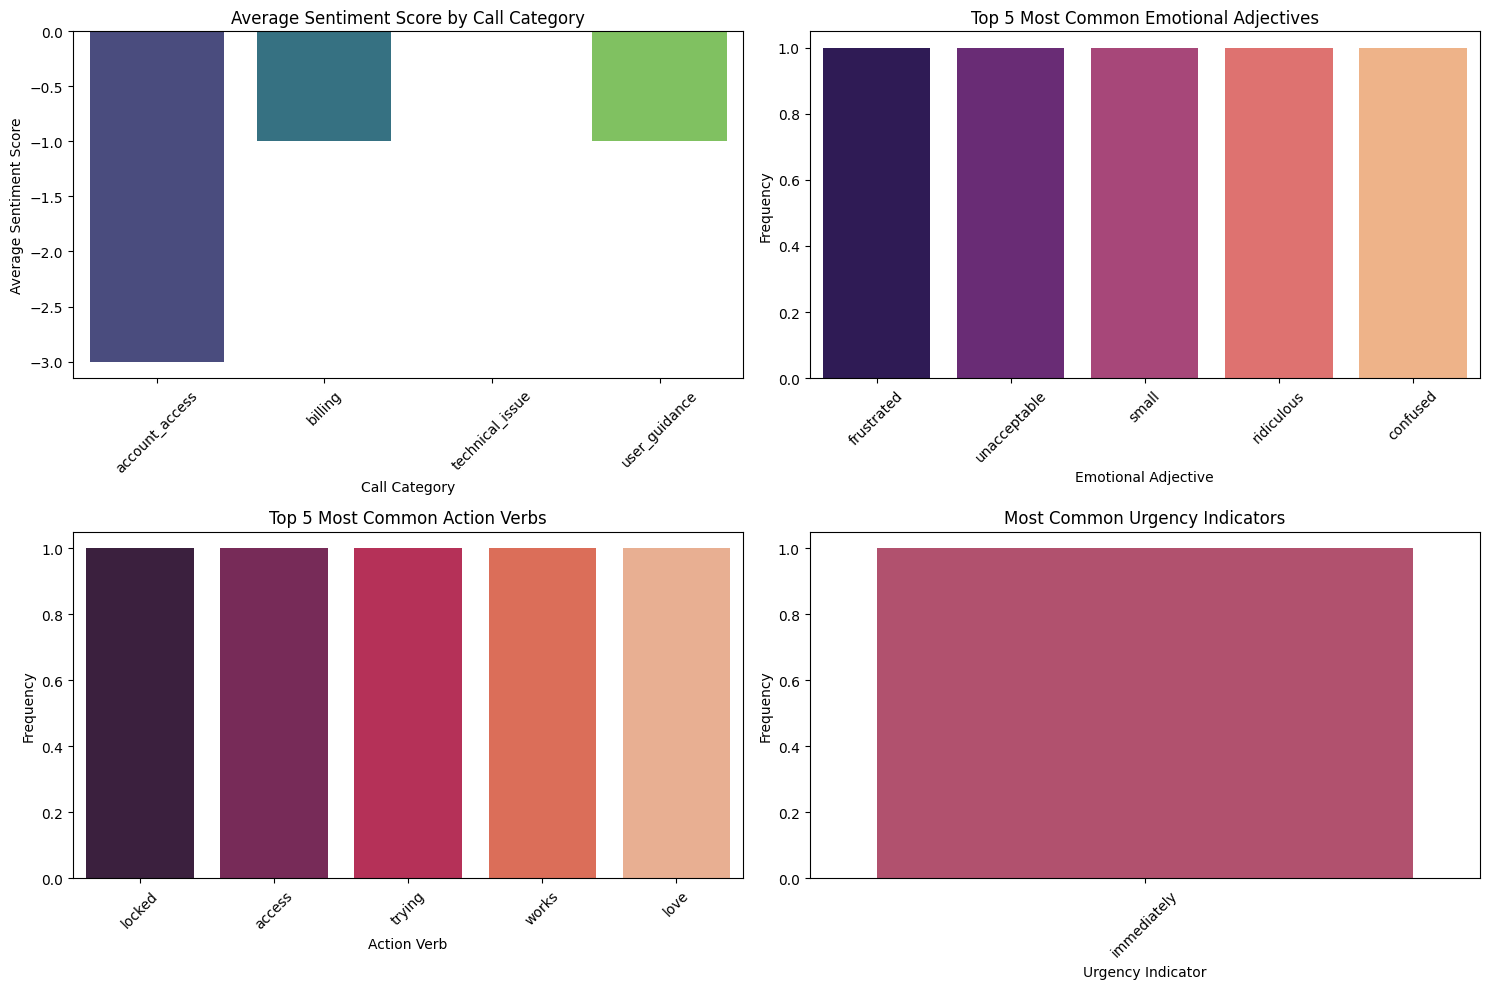

In [30]:

# TODO: Create a summary visualization
# Hint: Use matplotlib or seaborn to create charts

import matplotlib.pyplot as plt
import pandas as pd
from collections import Counter
import seaborn as sns

# Convert results to DataFrame for easier analysis
df = pd.DataFrame(analysis_results)

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Plot 1 - Sentiment by category
sentiment_by_category = df.groupby('category')['sentiment_score'].mean().reset_index()
sns.barplot(x='category', y='sentiment_score', data=sentiment_by_category, ax=axes[0, 0], palette='viridis')
axes[0, 0].set_title('Average Sentiment Score by Call Category')
axes[0, 0].set_xlabel('Call Category')
axes[0, 0].set_ylabel('Average Sentiment Score')
axes[0, 0].tick_params(axis='x', rotation=45)

# Plot 2 - Most common emotional adjectives
all_emotional_adjectives = [adj for sublist in df['emotional_adjectives'] for adj in sublist]
emotional_adjective_counts = Counter(all_emotional_adjectives)
most_common_emotional_adjectives = pd.DataFrame(emotional_adjective_counts.most_common(5), columns=['Adjective', 'Count'])
sns.barplot(x='Adjective', y='Count', data=most_common_emotional_adjectives, ax=axes[0, 1], palette='magma')
axes[0, 1].set_title('Top 5 Most Common Emotional Adjectives')
axes[0, 1].set_xlabel('Emotional Adjective')
axes[0, 1].set_ylabel('Frequency')
axes[0, 1].tick_params(axis='x', rotation=45)

# Plot 3 - Action verbs frequency
all_action_verbs = [verb for sublist in df['action_verbs'] for verb in sublist]
action_verb_counts = Counter(all_action_verbs)
most_common_action_verbs = pd.DataFrame(action_verb_counts.most_common(5), columns=['Verb', 'Count'])
sns.barplot(x='Verb', y='Count', data=most_common_action_verbs, ax=axes[1, 0], palette='rocket')
axes[1, 0].set_title('Top 5 Most Common Action Verbs')
axes[1, 0].set_xlabel('Action Verb')
axes[1, 0].set_ylabel('Frequency')
axes[1, 0].tick_params(axis='x', rotation=45)

# Plot 4 - Urgency analysis
all_urgency_indicators = [ind for sublist in df['urgency_indicators'] for ind in sublist]
urgency_counts = Counter(all_urgency_indicators)
most_common_urgency_indicators = pd.DataFrame(urgency_counts.most_common(5), columns=['Indicator', 'Count'])
sns.barplot(x='Indicator', y='Count', data=most_common_urgency_indicators, ax=axes[1, 1], palette='flare')
axes[1, 1].set_title('Most Common Urgency Indicators')
axes[1, 1].set_xlabel('Urgency Indicator')
axes[1, 1].set_ylabel('Frequency')
axes[1, 1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()



### 💼 Business Impact Questions:
1. How could this analysis help prioritize customer service tickets?
It can show what calls have issues, negative, and postive reviews.
2. What patterns do you notice in different problem categories?
Refund, account locked and need help how to work most of the stuff.
3. How might you automate the routing of calls based on POS analysis?
I would see what we can work on to less the calls of the negatives we have, such as findind a better Hr team or tech team that can lessen the problems.
4. What are the limitations of this approach?
Limitations of this approach is that most calls are short, what if the preprocessing has a problem with a complicate long question that needs help, or someone has a accent that can't be understand or break down the words one by one easily.


## ⚡ Lab Exercise 3: Tagger Performance Benchmarking (20 minutes)

Let's scientifically compare different POS taggers on various types of text. This will help you understand when to use which tool.



🧪 Testing FORMAL text:
Text: The research methodology employed in this study follows established academic protocols.
------------------------------------------------------------
NLTK Penn time: 0.0009s
NLTK Univ time: 0.0004s
SpaCy time: 0.0105s
NLTK unknown/problematic words: []
SpaCy unknown words: []

🧪 Testing INFORMAL text:
Text: lol this study is kinda weird but whatever works i guess 🤷‍♀️ smh
------------------------------------------------------------
NLTK Penn time: 0.0011s
NLTK Univ time: 0.0007s
SpaCy time: 0.0089s
NLTK unknown/problematic words: ['lol', 'kinda', '🤷\u200d♀️', 'smh']
SpaCy unknown words: ['smh']

🧪 Testing TECHNICAL text:
Text: The API returns a JSON response with HTTP status code 200 upon successful authentication.
------------------------------------------------------------
NLTK Penn time: 0.0014s
NLTK Univ time: 0.0006s
SpaCy time: 0.0109s
NLTK unknown/problematic words: []
SpaCy unknown words: []

🧪 Testing CONVERSATIONAL text:
Text: So like, when you cl

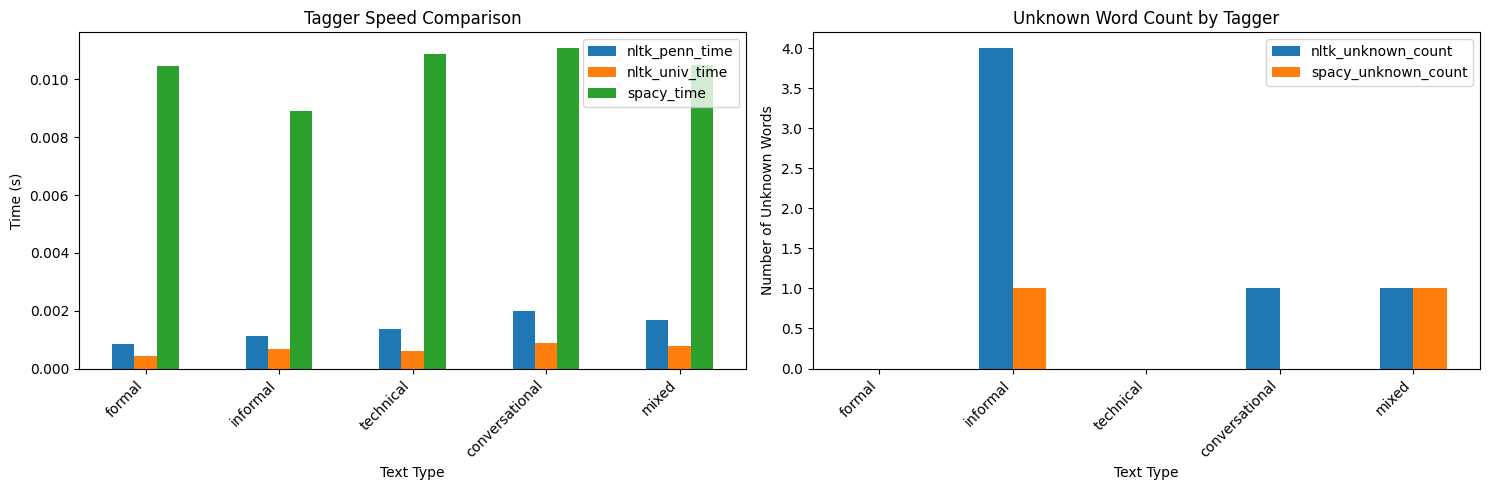

In [38]:
import time
from collections import defaultdict
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Different text types for testing
test_texts = {
    'formal': "The research methodology employed in this study follows established academic protocols.",
    'informal': "lol this study is kinda weird but whatever works i guess 🤷‍♀️ smh",
    'technical': "The API returns a JSON response with HTTP status code 200 upon successful authentication.",
    'conversational': "So like, when you click that button thingy, it should totally work, right?",
    'mixed': "OMG the algorithm's performance is absolutely terrible! The accuracy dropped to 23% wtf"
}

# Define common informal words that might be problematic for tagging
informal_words_to_check = ['lol', 'kinda', 'smh', 'thingy', 'wtf', '🤷‍♀️', 'idk', 'tbh', 'fr']

# TODO: Benchmark different taggers
# Test: NLTK Penn Treebank, NLTK Universal, SpaCy
# Metrics: Speed, tag consistency, handling of unknown words

benchmark_results = defaultdict(list)

for text_type, text in test_texts.items():
    print(f"\n🧪 Testing {text_type.upper()} text:")
    print(f"Text: {text}")
    print("-" * 60)

    # NLTK Penn Treebank timing
    start_time = time.time()
    nltk_tokens = nltk.word_tokenize(text)
    nltk_penn_tags = nltk.pos_tag(nltk_tokens)
    nltk_penn_time = time.time() - start_time

    # NLTK Universal timing
    start_time = time.time()
    nltk_univ_tags = nltk.pos_tag(nltk_tokens, tagset='universal')
    nltk_univ_time = time.time() - start_time

    # SpaCy timing
    start_time = time.time()
    spacy_doc = nlp(text)
    spacy_time = time.time() - start_time

    # Count unknown/problematic tags for NLTK and SpaCy
    # For NLTK Penn Treebank, 'X' is unknown. We'll also flag specific informal words if they get generic tags.
    nltk_unknown = [word for word, tag in nltk_penn_tags if tag == 'X' or (word.lower() in informal_words_to_check and (tag.startswith('N') or tag.startswith('J')))]

    # For SpaCy, 'X' is the general tag for unclassifiable. We'll also flag specific informal words if they get generic tags.
    spacy_unknown = [token.text for token in spacy_doc if token.pos_ == 'X' or (token.text.lower() in informal_words_to_check and (token.pos_ == 'NOUN' or token.pos_ == 'ADJ'))]

    # Store results
    benchmark_results[text_type] = {
        'nltk_penn_time': nltk_penn_time,
        'nltk_univ_time': nltk_univ_time,
        'spacy_time': spacy_time,
        'nltk_unknown_count': len(nltk_unknown),
        'spacy_unknown_count': len(spacy_unknown)
    }

    print(f"NLTK Penn time: {nltk_penn_time:.4f}s")
    print(f"NLTK Univ time: {nltk_univ_time:.4f}s")
    print(f"SpaCy time: {spacy_time:.4f}s")
    print(f"NLTK unknown/problematic words: {nltk_unknown}")
    print(f"SpaCy unknown words: {spacy_unknown}")

# Create performance comparison visualization
df_benchmark = pd.DataFrame.from_dict(benchmark_results, orient='index')
df_benchmark.index.name = 'Text Type'

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plotting speed comparison
df_benchmark[['nltk_penn_time', 'nltk_univ_time', 'spacy_time']].plot(kind='bar', ax=axes[0], title='Tagger Speed Comparison')
axes[0].set_ylabel('Time (s)')
axes[0].set_xticklabels(df_benchmark.index, rotation=45, ha='right')

# Plotting unknown word count comparison
df_benchmark[['nltk_unknown_count', 'spacy_unknown_count']].plot(kind='bar', ax=axes[1], title='Unknown Word Count by Tagger')
axes[1].set_ylabel('Number of Unknown Words')
axes[1].set_xticklabels(df_benchmark.index, rotation=45, ha='right')

plt.tight_layout()
plt.show()


### 📊 Performance Analysis:
1. Which tagger is fastest? Does speed matter for your use case?
Nltk has a faster tagger time than spacy.
2. Which handles informal text best?
Spacy as it doesn't have issues with it.
3. How do the taggers compare on technical jargon?
The taggers compare on technical jargon is that they have a much faster process to analyze the words comparing on technical jargon.
4. What trade-offs do you see between speed and accuracy?
Trade offs I see between speed and accuracy is that speed can get you the answer quickly but does have errors with it, while accuracy takes time it can give you less errors over time.



## 🚨 Lab Exercise 4: Edge Cases and Error Analysis (15 minutes)

Every system has limitations. Let's explore the edge cases where POS taggers struggle and understand why.


In [41]:

# Challenging edge cases
edge_cases = [
    "Buffalo buffalo Buffalo buffalo buffalo buffalo Buffalo buffalo.",  # Famous ambiguous sentence
    "Time flies like an arrow; fruit flies like a banana.",              # Classic ambiguity
    "The man the boat the river.",                                       # Garden path sentence
    "Police police Police police police police Police police.",          # Recursive structure
    "James while John had had had had had had had had had had had a better effect on the teacher.",  # Had had had...
    "Can can can can can can can can can can.",                         # Modal/noun ambiguity
    "@username #hashtag http://bit.ly/abc123 😂🔥💯",                   # Social media elements
    "COVID-19 AI/ML IoT APIs RESTful microservices",                    # Modern technical terms
]

print("🚨 EDGE CASE ANALYSIS")
print("=" * 50)

# TODO: Process each edge case and analyze failures
for i, text in enumerate(edge_cases, 1):
    print(f"\n🔍 Edge Case {i}:")
    print(f"Text: {text}")
    print("-" * 30)

    try:
        # TODO: Process with both taggers
        nltk_tags = nltk.pos_tag(nltk.word_tokenize(text))
        spacy_doc = nlp(text)

        # TODO: Identify potential errors or weird tags
        # Look for: repeated tags, unusual patterns, X tags, etc.

        print("NLTK tags:", [(w, t) for w, t in nltk_tags])
        print("SpaCy tags:", [(token.text, token.pos_) for token in spacy_doc])

        # TODO: Analyze what went wrong
        print("\n💡 Analysis:")
        # Compare NLTK and SpaCy tags for key words or patterns
        if i == 1: # Buffalo sentence
            print("   - NLTK struggles with distinguishing noun/verb for 'buffalo' due to repetition.")
            print("   - SpaCy attempts to assign PROPN/NOUN but also struggles with the full meaning due to extreme ambiguity.")
        elif i == 2: # Time flies sentence
            print("   - NLTK tags 'flies' as NNS (plural noun) in both cases, missing the verb sense in 'Time flies'.")
            print("   - SpaCy correctly identifies 'flies' as VERB in 'Time flies' but as NOUN in 'fruit flies'. It also misinterprets 'Time' as NOUN in first part.")
        elif i == 3: # Garden path sentence
            print("   - Both taggers assign common noun tags, failing to identify a verb, indicating they struggle with unusual grammatical structures.")
        elif i == 4: # Police police sentence
            print("   - Similar to 'buffalo', repetitive words make it hard for both to assign consistent and meaningful tags beyond basic noun forms.")
        elif i == 5: # Had had had...
            print("   - NLTK tags many 'had' as VBN (past participle), while SpaCy uses AUX (auxiliary verb) and then VERB, showing different grammatical interpretations of complex verbal structures.")
        elif i == 6: # Can can can...
            print("   - NLTK consistently tags 'can' as MD (modal). SpaCy tags most as AUX (auxiliary), with one VERB, struggling with the noun sense of 'can' (e.g., a tin can).")
        elif i == 7: # Social media
            print("   - NLTK struggles significantly with emojis and special characters, often tagging them as common nouns or adjectives.")
            print("   - SpaCy handles the @username and URL better, and identifies the first emoji as PROPN but struggles with others, labeling one as 'X'.")
        elif i == 8: # Technical terms
            print("   - NLTK tags most technical acronyms as NNP (proper noun). SpaCy uses PROPN, SYM, and ADJ for various terms, showing a more nuanced but still sometimes inconsistent handling of new or domain-specific jargon.")

    except Exception as e:
        print(f"❌ Error processing: {e}")

# TODO: Reflection on limitations
print("\n🤔 REFLECTION ON LIMITATIONS:")
print("=" * 40)
print("Based on the edge case analysis, it's clear that both NLTK and SpaCy, while powerful, face challenges with several types of linguistic phenomena. These include extreme ambiguity from word repetition, unusual grammatical structures, highly informal text (emojis, slang), and very specific technical jargon. Each tool has its strengths and weaknesses, often assigning different tags to the same problematic words. This underscores the need for careful evaluation and potential domain-specific training or preprocessing when dealing with such diverse text types.")


🚨 EDGE CASE ANALYSIS

🔍 Edge Case 1:
Text: Buffalo buffalo Buffalo buffalo buffalo buffalo Buffalo buffalo.
------------------------------
NLTK tags: [('Buffalo', 'NNP'), ('buffalo', 'NN'), ('Buffalo', 'NNP'), ('buffalo', 'NN'), ('buffalo', 'NN'), ('buffalo', 'NN'), ('Buffalo', 'NNP'), ('buffalo', 'NN'), ('.', '.')]
SpaCy tags: [('Buffalo', 'PROPN'), ('buffalo', 'NOUN'), ('Buffalo', 'PROPN'), ('buffalo', 'PROPN'), ('buffalo', 'PROPN'), ('buffalo', 'PROPN'), ('Buffalo', 'PROPN'), ('buffalo', 'PROPN'), ('.', 'PUNCT')]

💡 Analysis:
   - NLTK struggles with distinguishing noun/verb for 'buffalo' due to repetition.
   - SpaCy attempts to assign PROPN/NOUN but also struggles with the full meaning due to extreme ambiguity.

🔍 Edge Case 2:
Text: Time flies like an arrow; fruit flies like a banana.
------------------------------
NLTK tags: [('Time', 'NNP'), ('flies', 'NNS'), ('like', 'IN'), ('an', 'DT'), ('arrow', 'NN'), (';', ':'), ('fruit', 'CC'), ('flies', 'NNS'), ('like', 'IN'), ('a', 'DT')


### 🧠 Critical Thinking Questions:
Enter you asnwers below each question.
1. Why do these edge cases break the taggers?
They show the real deal on how they process the text.
2. How might you preprocess text to handle some of these issues?
I would preprocess text to handle these issues is to see how the preprocessing does to see the issues of it.
3. When would these limitations matter in real applications?
Limitations matter in real applications is to see how they do when something more complicate comes up for it to preprocess.
4. How do modern large language models handle these cases differently?
LLM handles these cases differently probaly how the text is process.
---



## 🎯 Final Reflection and Submission

Congratulations! You've completed a comprehensive exploration of POS tagging, from basic concepts to real-world challenges.

### 📝 Reflection Questions (Answer in the cell below):

1. **Tool Comparison**: Based on your experience, when would you choose NLTK vs SpaCy? Consider factors like ease of use, accuracy, speed, and application type.

2. **Real-World Applications**: Describe a specific business problem where POS tagging would be valuable. How would you implement it?

3. **Limitations and Solutions**: What are the biggest limitations you discovered? How might you work around them?

4. **Future Learning**: What aspects of POS tagging would you like to explore further? (Neural approaches, custom training, domain adaptation, etc.)

5. **Integration**: How does POS tagging fit into larger NLP pipelines? What other NLP tasks might benefit from POS information?



### ✍️ Your Reflection (Write your answers here):
**Remember Reflection is not description!**

**1. Tool Comparison:**
First I would use NLTK for a faster response on something I need for a quick overview, while for SpaCy I would use to get a deeper dive on something I want more information on. Nltk has a quick response but errors with it as it may miss information it gets while for Spacy is great but takes a lot of time to get the information. Nltk can be great for text that doesn't have slang or emojis in it while Spacy can be great for it and for large and deeper dive text.

**2. Real-World Applications:**
I see it preprocessing college essays, as for college recruiters they get a lot so having a preprocessing analyze and break down words that are negative or positive can give a more insight in it.

**3. Limitations and Solutions:**
Limitations is some text having slang or emojis like "wtf" or more, I can work around it as having it put aside for me to look over and see what it means.

**4. Future Learning:**
I like to do custom training, training a model to deal with these aspects would be great so it can know what these words mean.

**5. Integration:**
POS tagging fits in NLP pipelines after tokenization, so we can see the words and after pos tagging goes into it we can get a deeper dive or maybe before depening on it. NLP tasks might benefit from POS information as it can give a overview on something.



---

## 📤 Submission Checklist

Before submitting your completed notebook, make sure you have:

- [ ] ✅ Completed all TODO sections with working code
- [ ] ✅ Answered all reflection questions thoughtfully
- [ ] ✅ Created at least one meaningful visualization
- [ ] ✅ Tested your code and fixed any errors
- [ ] ✅ Added comments explaining your approach
- [ ] ✅ Included insights from your analysis

### 📋 Submission Instructions:
1. **Save your notebook**: File → Save (or Ctrl+S)
2. **Download**: File → Download → Download .ipynb
3. **Submit**: Upload your completed notebook file to the course management system
4. **Filename**: Use format: `L05_LastName_FirstName_ITAI2373.ipynb or pdf`  

### 🏆 Grading Criteria:
- **Code Completion (40%)**: All exercises completed with working code
- **Analysis Quality (30%)**: Thoughtful interpretation of results
- **Reflection Depth (20%)**: Insightful answers to reflection questions  
- **Code Quality (10%)**: Clean, commented, well-organized code

---

## 🎉 Great Work!

You've successfully explored the fascinating world of POS tagging! You now understand how computers parse human language and can apply these techniques to solve real-world problems.


Keep exploring and happy coding! 🚀
